# Exercício — Fronteiras de Decisão com Diferentes Kernels de SVM (Support Vector Machines)

Neste exercício, investigamos o comportamento do algoritmo **Support Vector Machine (SVM)** para classificação binária em um espaço bidimensional, analisando como diferentes funções de **Kernel** e seus respectivos hiperparâmetros moldam as **fronteiras de decisão**, as **margens de separação** e os **vetores de suporte**.

Serão investigados:
- Os quatro kernels fundamentais do scikit-learn: **Linear**, **Polinomial**, **RBF (Gaussiano)** e **Sigmoid**;
- A identificação geométrica e o papel dos **Vetores de Suporte**;
- O impacto do hiperparâmetro de regularização **$C$** (margem rígida vs. margem suave);
- O impacto do hiperparâmetro **$\gamma$ (gamma)** no alcance local do Kernel RBF;
- O efeito do grau (**$degree$**) no Kernel Polinomial;
- Comparação quantitativa de desempenho e parcimônia dos modelos.


## 1. Fundamentação Teórica dos Kernels SVM

O classificador SVM busca encontrar o hiperplano ótimo que maximiza a margem de separação entre as classes:

$$f(x) = \text{sign}\left( \mathbf{w}^T \phi(x) + b \right) = \text{sign}\left( \sum_{i \in \text{SV}} \alpha_i y_i K(x_i, x) + b \right)$$

Onde apenas os **Vetores de Suporte** ($\alpha_i > 0$) contribuem ativamente para a definição da fronteira. Através do **Kernel Trick**, a função de similaridade $K(x_i, x) = \langle \phi(x_i), \phi(x) \rangle$ calcula o produto interno no espaço transformado de alta dimensão sem computar explicitamente as coordenadas de $\phi(x)$.

Os kernels investigados são definidos por:

1. **Linear:**
$$K(x, z) = x^T z$$

2. **Polinomial:**
$$K(x, z) = (\gamma x^T z + r)^d$$

3. **RBF (Radial Basis Function / Gaussiano):**
$$K(x, z) = \exp\left(-\gamma \|x - z\|^2\right), \quad \text{onde } \gamma = \frac{1}{2\sigma^2}$$

4. **Sigmoid (Tangente Hiperbólica):**
$$K(x, z) = \tanh(\gamma x^T z + r)$$


## 2. Carregamento e Visualização do Espaço de Atributos

Definimos o conjunto de dados sintético bidimensional composto por 16 amostras distribuídas entre duas classes ($y \in \{0, 1\}$).


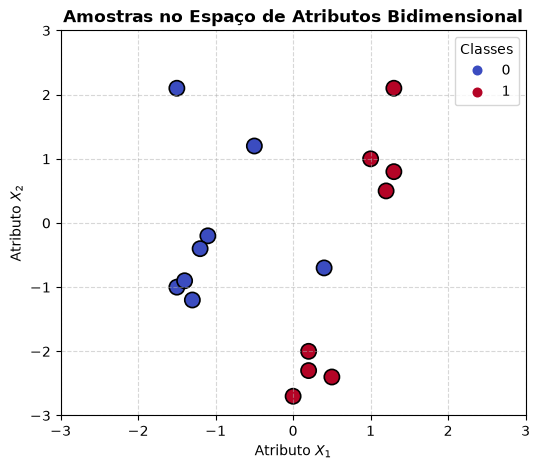

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn import svm
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score

# Definição do conjunto de dados bidimensional
X = np.array(
    [
        [0.4, -0.7],
        [-1.5, -1.0],
        [-1.4, -0.9],
        [-1.3, -1.2],
        [-1.1, -0.2],
        [-1.2, -0.4],
        [-0.5, 1.2],
        [-1.5, 2.1],
        [1.0, 1.0],
        [1.3, 0.8],
        [1.2, 0.5],
        [0.2, -2.0],
        [0.5, -2.4],
        [0.2, -2.3],
        [0.0, -2.7],
        [1.3, 2.1],
    ]
)

y = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])

# Visualização inicial das amostras no espaço 2D
fig, ax = plt.subplots(figsize=(6, 5))
x_min, x_max, y_min, y_max = -3, 3, -3, 3
ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

scatter = ax.scatter(X[:, 0], X[:, 1], s=120, c=y, cmap=plt.cm.coolwarm, edgecolors="k", linewidth=1.2)
ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
ax.set_title("Amostras no Espaço de Atributos Bidimensional", fontsize=12, fontweight="bold")
ax.set_xlabel("Atributo $X_1$")
ax.set_ylabel("Atributo $X_2$")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Perguntas

1. Quantas amostras e atributos existem no conjunto?
2. Como as classes estão distribuídas no espaço de atributos?
3. O conjunto é perfeitamente separável por um hiperplano linear (reta)?

**Responda aqui.**

1. O conjunto possui 16 amostras e 2 atributos contínuos ($X_1$ e $X_2$), divididas igualmente em duas classes (8 amostras na classe 0 e 8 amostras na classe 1).
2. A classe 0 concentra-se no lado esquerdo ($X_1 < 0$), exceto pelo ponto $(0.4, -0.7)$, enquanto a classe 1 ocupa o quadrante superior direito ($X_1 > 0, X_2 > 0$) e a região inferior central/direita ($X_2 \le -2.0$).
3. Não. Devido ao ponto da classe 0 em $(0.4, -0.7)$ posicionado próximo à região da classe 1, não é possível traçar uma reta única que separe perfeitamente todas as instâncias sem cometer pelo menos um erro de classificação.


## 3. Função para Treinamento e Plotagem das Fronteiras de Decisão

Criamos uma função modular que treina o classificador `SVC`, exibe a região de decisão (`pcolormesh`), as margens de decisão em contorno ($f(x) \in \{-1, 0, 1\}$) e destaca os **Vetores de Suporte** com círculos pretos ampliados.


In [2]:
def plot_training_data_with_decision_boundary(
    kernel, C=1.0, gamma=2, degree=3, coef0=0.0, ax=None, long_title=True, support_vectors=True
):
    # Treinamento do classificador SVC
    clf = svm.SVC(kernel=kernel, C=C, gamma=gamma, degree=degree, coef0=coef0).fit(X, y)

    # Configurações do eixo e limites
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    x_min, x_max, y_min, y_max = -3, 3, -3, 3
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

    # Plotagem da região de decisão e das margens
    common_params = {"estimator": clf, "X": X, "ax": ax}
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,
        cmap=plt.cm.coolwarm
    )
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="decision_function",
        plot_method="contour",
        levels=[-1, 0, 1],
        colors=["k", "k", "k"],
        linestyles=["--", "-", "--"],
        linewidths=[1.2, 2.0, 1.2]
    )

    # Destaque dos vetores de suporte (círculos ampliados)
    if support_vectors:
        ax.scatter(
            clf.support_vectors_[:, 0],
            clf.support_vectors_[:, 1],
            s=180,
            facecolors="none",
            edgecolors="k",
            linewidth=1.8,
            label=f"Vetores de Suporte ({len(clf.support_vectors_)})"
        )

    # Plotagem dos pontos de dados
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap=plt.cm.coolwarm, edgecolors="k", linewidth=1.0)
    
    # Título e formatação
    acc = accuracy_score(y, clf.predict(X)) * 100
    if long_title:
        ax.set_title(f"Kernel: {kernel.upper()} | Acurácia: {acc:.1f}% | SVs: {len(clf.support_vectors_)}", fontsize=11, fontweight="bold")
    else:
        ax.set_title(f"{kernel} (Acc: {acc:.0f}%, SVs: {len(clf.support_vectors_)})", fontsize=10)
    
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.grid(True, linestyle=":", alpha=0.6)
    
    return clf


## 4. Experimento 1 — Comparação dos Quatro Kernels Base

Avaliamos os quatro kernels padrão (`linear`, `poly`, `rbf`, `sigmoid`) com $\gamma = 2$ e $C = 1.0$.


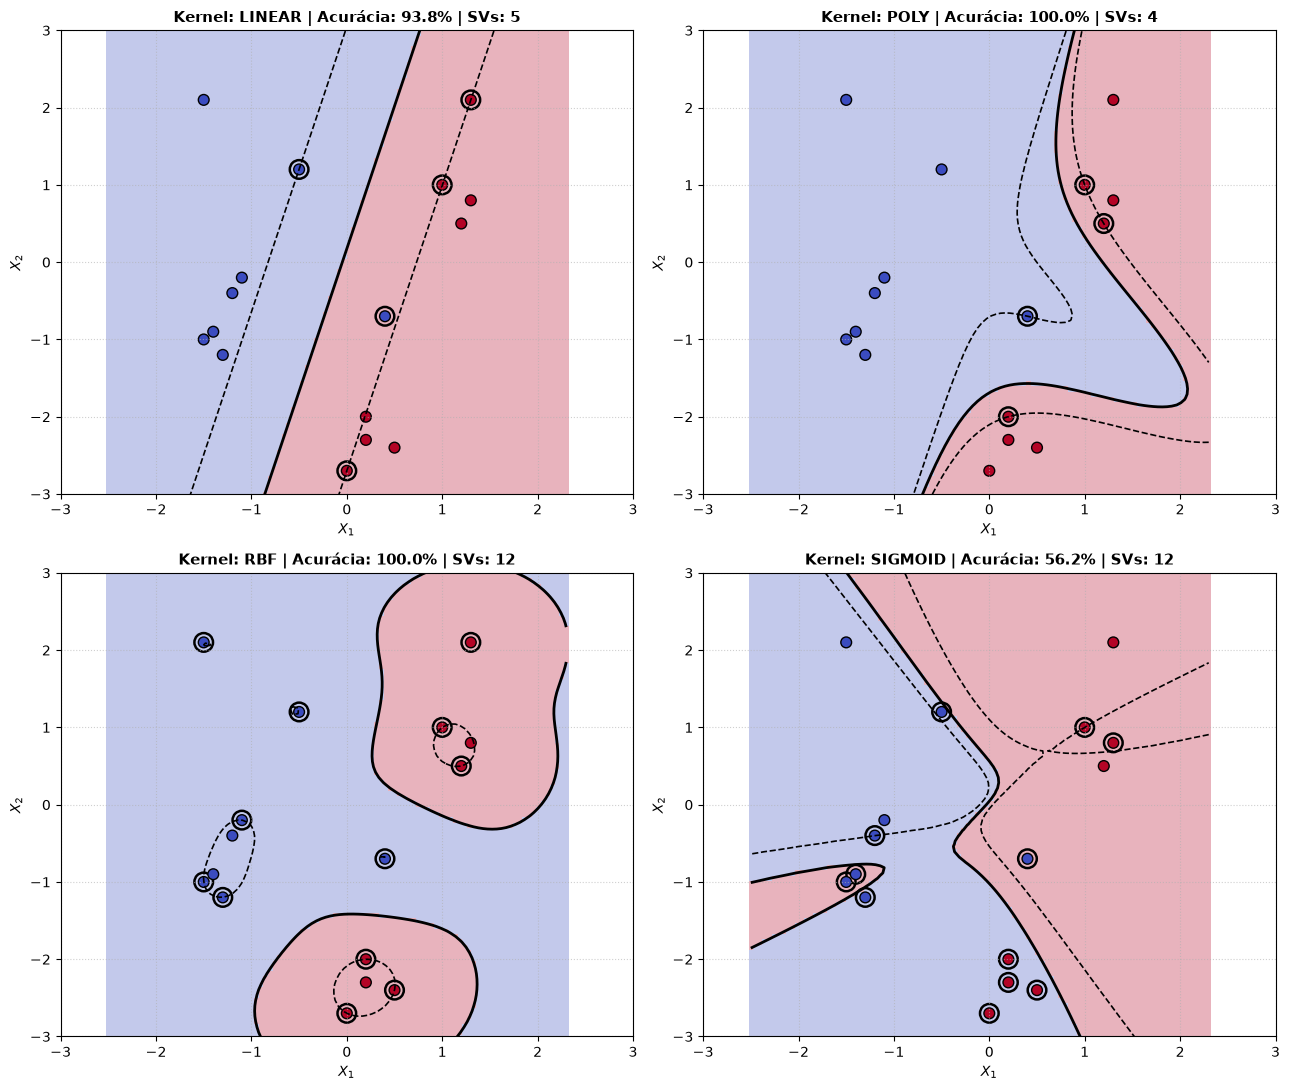

In [3]:
kernels = ["linear", "poly", "rbf", "sigmoid"]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.ravel()

for i, kernel in enumerate(kernels):
    plot_training_data_with_decision_boundary(
        kernel=kernel, gamma=2, C=1.0, ax=axes[i], long_title=True
    )

plt.tight_layout()
plt.show()


### Perguntas

1. Como cada um dos quatro kernels moldou a fronteira de decisão?
2. Por que o kernel Linear cometeu um erro de classificação ($15/16 = 93.8\%$)?
3. Como o kernel Polinomial ($d=3$) conseguiu atingir $100\%$ de acurácia com apenas 4 vetores de suporte?
4. Por que o kernel RBF apresentou $100\%$ de acurácia, mas utilizou 12 vetores de suporte?
5. Por que o kernel Sigmoid teve o pior desempenho ($56.2\%$ de acurácia)?

**Responda aqui.**

1. - **Linear:** Gera uma reta (hiperplano linear) com margem plana;
   - **Polinomial ($d=3$):** Gera uma curva suave cúbica que contorna perfeitamente a separação entre as classes;
   - **RBF:** Cria fronteiras circulares/elípticas isoladas em torno dos agrupamentos de pontos;
   - **Sigmoid:** Produz uma fronteira hiperbólica distorcida, inadequada para a geometria deste conjunto.
2. O conjunto não é linearmente separável: o ponto da classe 0 em $(0.4, -0.7)$ fica do lado incorreto da margem linear. Como $C=1.0$, o modelo permite uma violação de margem suave em vez de distorcer a reta.
3. O kernel cúbico mapeia os dados para um espaço de dimensão 9 ($\mathbb{R}^2 \to \mathbb{R}^9$), encontrando uma superfície suave onde as classes são perfeitamente separáveis utilizando apenas 4 pontos críticos como vetores de suporte (alta parcimônia).
4. O valor $\gamma=2$ é relativamente elevado, fazendo com que as funções de base radial tenham um raio de influência estreito. Para envolver os pontos, o SVM precisa de mais amostras atuando como centros das gaussianas (12 de 16 amostras viraram vetores de suporte).
5. O kernel Sigmoid com $\gamma=2$ e $r=0$ não satisfaz estritamente a condição de Mercer em todo o domínio e sofre com saturação da função $\tanh$, gerando hiperplanos inadequados.


## 5. Experimento 2 — Efeito do Hiperparâmetro $C$ (Regularização)

O hiperparâmetro $C$ controla o equilíbrio entre **maximizar a margem** e **minimizar os erros de classificação** no conjunto de treinamento:

$$\min_{\mathbf{w}, b, \xi} \frac{1}{2}\|\mathbf{w}\|^2 + C \sum_{i=1}^n \xi_i$$

- **$C$ pequeno:** Prioriza margem larga, tolerando mais violações e erros de classificação (*soft margin* / maior viés, menor variância).
- **$C$ grande:** Penaliza severamente qualquer erro, forçando margem estreita para classificar todos os pontos corretamente (*hard margin* / menor viés, risco de *overfitting*).


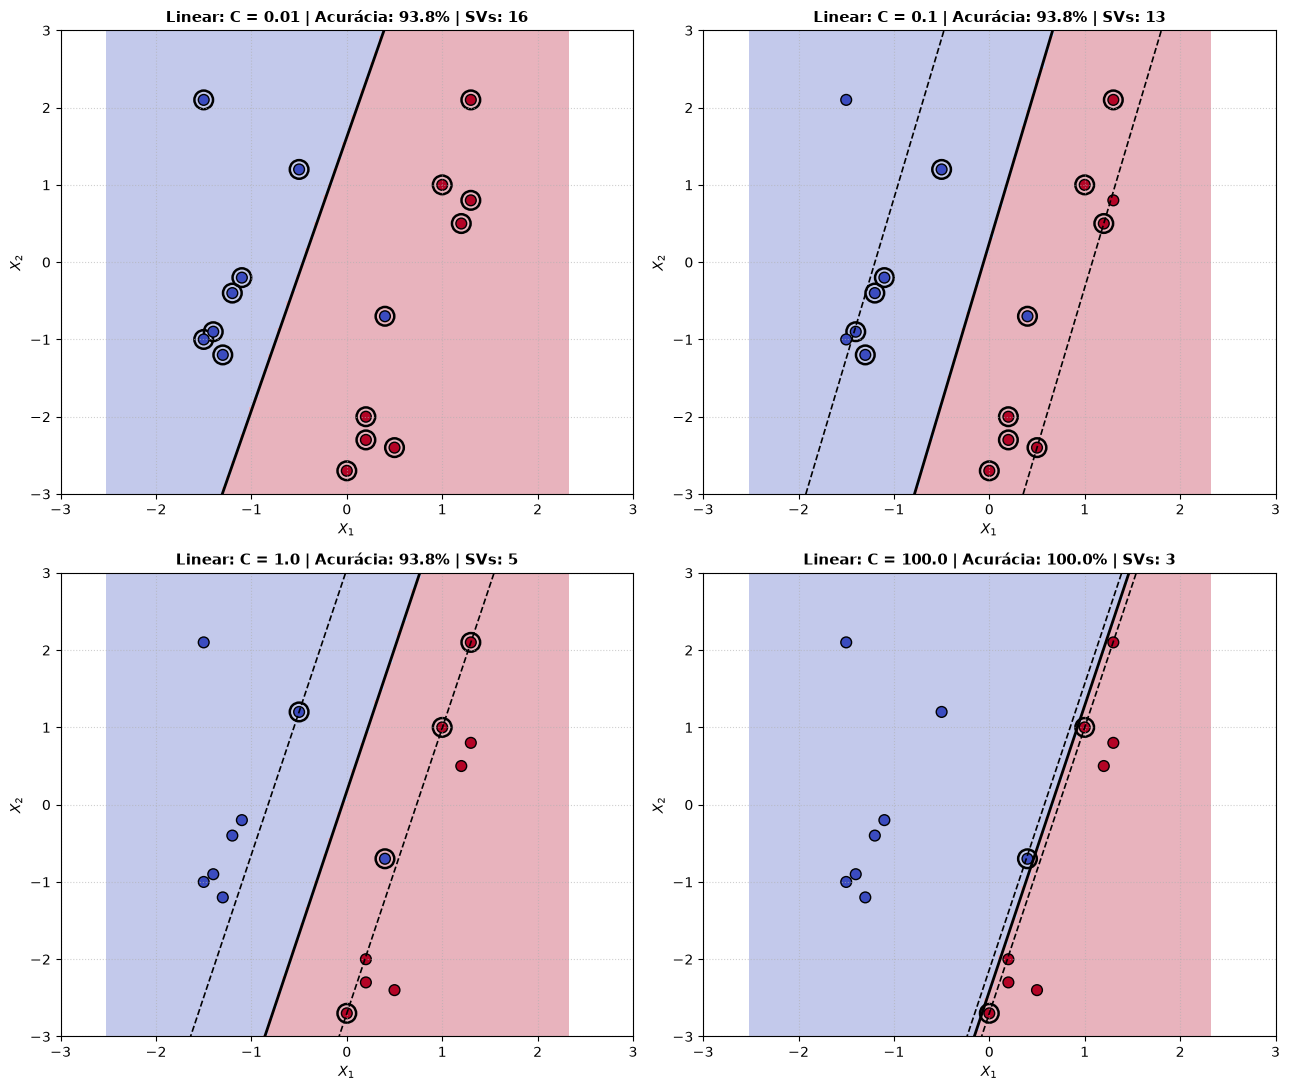

In [4]:
valores_C = [0.01, 0.1, 1.0, 100.0]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.ravel()

for i, c_val in enumerate(valores_C):
    clf = svm.SVC(kernel="linear", C=c_val).fit(X, y)
    acc = accuracy_score(y, clf.predict(X)) * 100
    n_sv = len(clf.support_vectors_)
    
    plot_training_data_with_decision_boundary(
        kernel="linear", C=c_val, ax=axes[i], long_title=False
    )
    axes[i].set_title(f"Linear: C = {c_val} | Acurácia: {acc:.1f}% | SVs: {n_sv}", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


### Perguntas

1. O que acontece com a margem e o número de vetores de suporte quando $C$ é muito pequeno ($C = 0.01$)?
2. O que acontece quando $C$ aumenta para $100.0$?
3. Como o valor de $C$ influencia o trade-off entre viés e variância?

**Responda aqui.**

1. Com $C = 0.01$, a penalidade por erro é mínima. A margem de separação fica muito larga e todas as 16 instâncias passam a se comportar como vetores de suporte (ficam dentro da margem ou a violam).
2. Com $C = 100.0$, a penalidade por erros é altíssima. A margem se estreita drasticamente para evitar qualquer violação e a reta é forçada a classificar o ponto $(0.4, -0.7)$ corretamente, atingindo 100% de acurácia com apenas 3 vetores de suporte.
3. $C$ pequeno gera modelos com **alto viés e baixa variância** (mais simples, margem ampla, tolerante a ruído). $C$ grande gera modelos com **baixo viés e alta variância** (mais complexos, margem estreita, sensíveis a outliers e com risco de overfitting).


## 6. Experimento 3 — Efeito do Hiperparâmetro $\gamma$ (Gamma) no Kernel RBF

No Kernel Gaussiano (RBF):

$$K(x, z) = \exp\left(-\gamma \|x - z\|^2\right)$$

O parâmetro $\gamma$ determina o inverso do raio de influência dos vetores de suporte:
- **$\gamma$ pequeno:** Raio de influência amplo $\rightarrow$ fronteira suave e quase linear (alto viés).
- **$\gamma$ grande:** Raio de influência restrito $\rightarrow$ fronteira ajustada intimamente a cada ponto, criando "ilhas" de decisão ao redor das amostras (alta variância / *overfitting*).


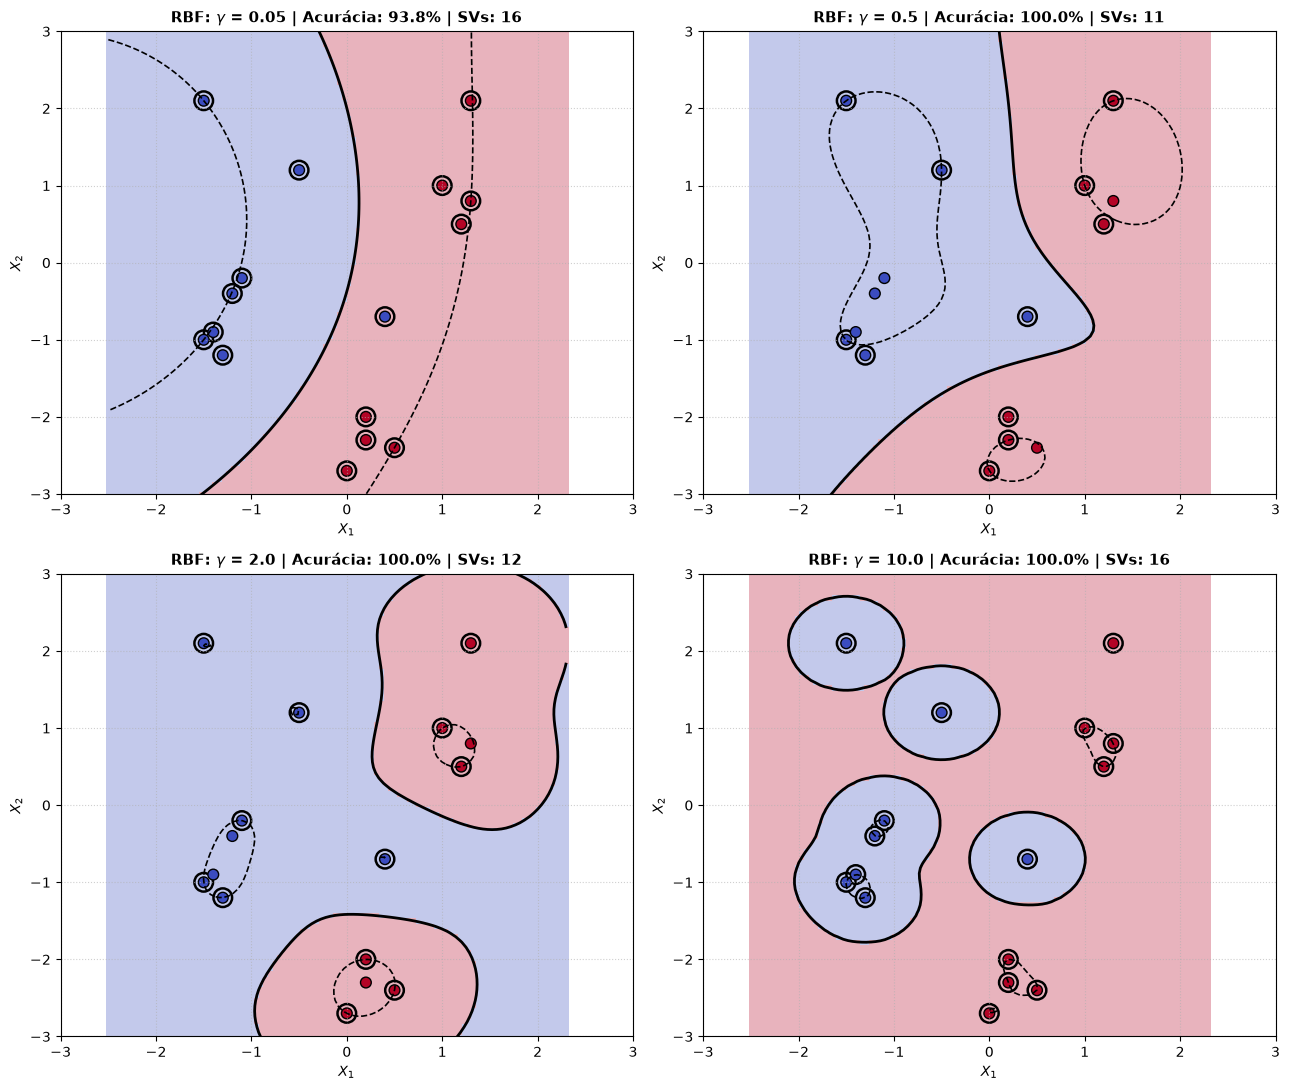

In [5]:
valores_gamma = [0.05, 0.5, 2.0, 10.0]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.ravel()

for i, g_val in enumerate(valores_gamma):
    clf = svm.SVC(kernel="rbf", gamma=g_val, C=1.0).fit(X, y)
    acc = accuracy_score(y, clf.predict(X)) * 100
    n_sv = len(clf.support_vectors_)
    
    plot_training_data_with_decision_boundary(
        kernel="rbf", gamma=g_val, C=1.0, ax=axes[i], long_title=False
    )
    axes[i].set_title(f"RBF: $\gamma$ = {g_val} | Acurácia: {acc:.1f}% | SVs: {n_sv}", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


### Perguntas

1. Como a fronteira do RBF se comporta com $\gamma = 0.05$?
2. O que ocorre visualmente quando $\gamma = 10.0$?
3. Por que um modelo com $\gamma = 10.0$ tem alto risco de generalizar mal em novos dados?

**Responda aqui.**

1. Com $\gamma = 0.05$, a influência de cada ponto é muito ampla. A fronteira de decisão é quase linear e suave, com margens muito largas e quase todos os pontos funcionando como vetores de suporte.
2. Com $\gamma = 10.0$, a função gaussiana decai muito rapidamente. O modelo cria pequenas "ilhas" isoladas em torno de cada ponto de treinamento, e todas as 16 instâncias tornam-se vetores de suporte.
3. Porque o modelo sofre de severo **overfitting**: qualquer ponto novo ligeiramente distante das amostras de treino cairá na classe padrão de fundo, perdendo completamente a capacidade de generalização da tendência global dos dados.


## 7. Experimento 4 — Efeito do Grau ($degree$) no Kernel Polinomial

O grau $d$ do kernel polinomial $K(x, z) = (\gamma x^T z + r)^d$ dita a flexibilidade da fronteira geométrica.


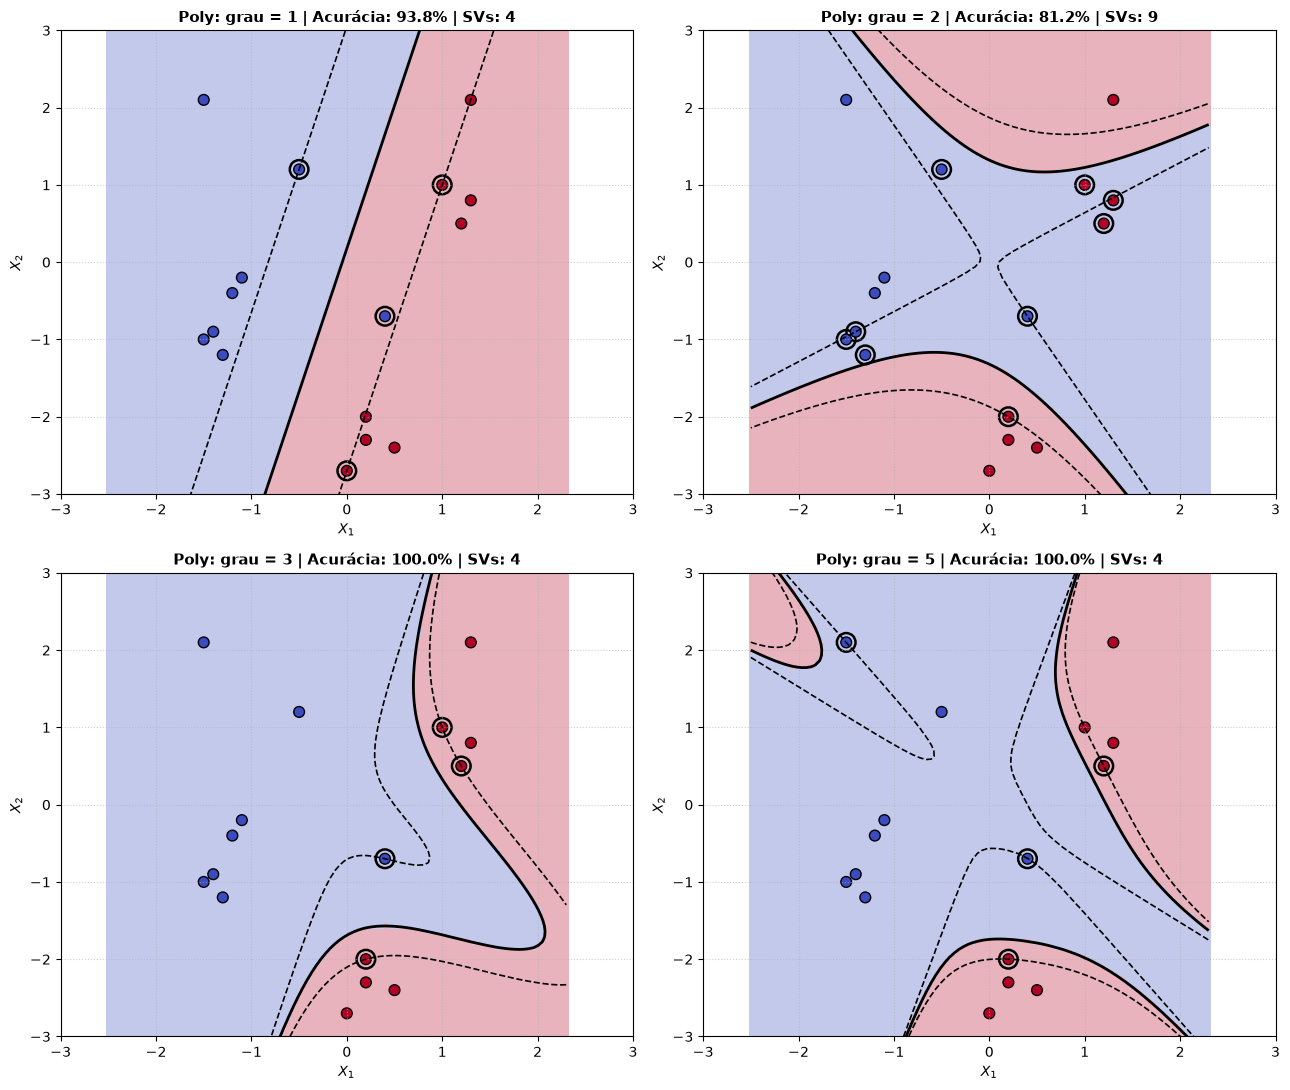

In [6]:
graus_poly = [1, 2, 3, 5]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.ravel()

for i, deg in enumerate(graus_poly):
    clf = svm.SVC(kernel="poly", degree=deg, gamma=2.0, C=1.0).fit(X, y)
    acc = accuracy_score(y, clf.predict(X)) * 100
    n_sv = len(clf.support_vectors_)
    
    plot_training_data_with_decision_boundary(
        kernel="poly", degree=deg, gamma=2.0, C=1.0, ax=axes[i], long_title=False
    )
    axes[i].set_title(f"Poly: grau = {deg} | Acurácia: {acc:.1f}% | SVs: {n_sv}", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


### Perguntas

1. Qual é a diferença na fronteira entre graus ímpares ($d=1, 3, 5$) e graus pares ($d=2$)?
2. Por que o grau 3 apresentou uma separação superior ao grau 2 neste conjunto de dados?

**Responda aqui.**

1. Graus pares ($d=2$) geram superfícies quadráticas (parábolas/elipses simétricas) com restrição de sinal, enquanto graus ímpares ($d=1, 3, 5$) preservam a assimetria direcional dos dados, permitindo curvas em "S" e transições de fase flexíveis.
2. Porque a distribuição das classes possui um formato de transição assimétrica em curva cúbica, a qual uma cônica de grau 2 não consegue contornar sem cortar incorretamente algumas regiões (atingindo apenas 81.2% no grau 2 contra 100% no grau 3).


## 8. Tabela Comparativa de Desempenho e Vetores de Suporte

Consolidamos todas as configurações testadas em uma tabela quantitativa para analisar a **Acurácia**, a **quantidade de Vetores de Suporte por classe** e a **taxa de compressão/parcimônia** do modelo.


In [7]:
modelos = [
    {"Kernel": "Linear", "Parâmetros": "C=1.0", "clf": svm.SVC(kernel="linear", C=1.0)},
    {"Kernel": "Linear", "Parâmetros": "C=100.0", "clf": svm.SVC(kernel="linear", C=100.0)},
    {"Kernel": "Polinomial", "Parâmetros": "grau=2, $\gamma$=2, C=1", "clf": svm.SVC(kernel="poly", degree=2, gamma=2, C=1.0)},
    {"Kernel": "Polinomial", "Parâmetros": "grau=3, $\gamma$=2, C=1", "clf": svm.SVC(kernel="poly", degree=3, gamma=2, C=1.0)},
    {"Kernel": "Polinomial", "Parâmetros": "grau=5, $\gamma$=2, C=1", "clf": svm.SVC(kernel="poly", degree=5, gamma=2, C=1.0)},
    {"Kernel": "RBF", "Parâmetros": "$\gamma$=0.1, C=1", "clf": svm.SVC(kernel="rbf", gamma=0.1, C=1.0)},
    {"Kernel": "RBF", "Parâmetros": "$\gamma$=2.0, C=1", "clf": svm.SVC(kernel="rbf", gamma=2.0, C=1.0)},
    {"Kernel": "RBF", "Parâmetros": "$\gamma$=10.0, C=1", "clf": svm.SVC(kernel="rbf", gamma=10.0, C=1.0)},
    {"Kernel": "Sigmoid", "Parâmetros": "$\gamma$=2.0, C=1", "clf": svm.SVC(kernel="sigmoid", gamma=2.0, C=1.0)},
]

resultados = []
for m in modelos:
    clf = m["clf"].fit(X, y)
    acc = accuracy_score(y, clf.predict(X)) * 100
    n_sv = len(clf.support_vectors_)
    sv_c0 = clf.n_support_[0]
    sv_c1 = clf.n_support_[1]
    prop_sv = (n_sv / len(X)) * 100
    
    resultados.append({
        "Kernel": m["Kernel"],
        "Parâmetros": m["Parâmetros"],
        "Acurácia (%)": f"{acc:.1f}%",
        "Total SVs": n_sv,
        "SVs Classe 0": sv_c0,
        "SVs Classe 1": sv_c1,
        "% Amostras como SV": f"{prop_sv:.1f}%"
    })

tabela_comparativa = pd.DataFrame(resultados)
tabela_comparativa


,Kernel,Parâmetros,Acurácia (%),Total SVs,SVs Classe 0,SVs Classe 1,% Amostras como SV
0,Linear,C=1.0,93.8%,5,2,3,31.2%
1,Linear,C=100.0,100.0%,3,1,2,18.8%
2,Polinomial,"grau=2, $\gamma$=2, C=1",81.2%,9,5,4,56.2%
3,Polinomial,"grau=3, $\gamma$=2, C=1",100.0%,4,1,3,25.0%
4,Polinomial,"grau=5, $\gamma$=2, C=1",100.0%,4,2,2,25.0%
5,RBF,"$\gamma$=0.1, C=1",93.8%,12,6,6,75.0%
6,RBF,"$\gamma$=2.0, C=1",100.0%,12,6,6,75.0%
7,RBF,"$\gamma$=10.0, C=1",100.0%,16,8,8,100.0%
8,Sigmoid,"$\gamma$=2.0, C=1",56.2%,12,6,6,75.0%


### Perguntas

1. Qual modelo apresentou o melhor equilíbrio entre acurácia máxima ($100\%$) e parcimônia (menor número de vetores de suporte)?
2. Por que um modelo com menor proporção de vetores de suporte é teoricamente preferível?
3. Como a escolha do kernel afeta a interpretabilidade e a complexidade computacional da inferência?

**Responda aqui.**

1. O **Kernel Polinomial de grau 3** ($\gamma=2, C=1$), pois atingiu 100% de acurácia utilizando apenas **4 vetores de suporte (25% do dataset)**, gerando uma fronteira limpa e bem condicionada.
2. Pelo princípio da Navalha de Occam e pela teoria de aprendizado estatístico (Vapnik): menos vetores de suporte significam que a função de decisão depende de menos pontos, resultando em menor variância, menor risco de overfitting e menor custo computacional no cálculo de predições $f(x) = \sum_{i \in SV} \alpha_i y_i K(x_i, x) + b$.
3. O kernel linear é o mais interpretável e rápido ($\mathcal{O}(d)$ operações por predição, onde $d$ é a dimensão original). Kernels não-lineares aumentam a complexidade para $\mathcal{O}(|\text{SV}| \cdot d)$ e tornam a fronteira menos intuitiva geometricamente no espaço de entrada original.


# Conclusão

- **Fronteiras Não-Lineares:** O *Kernel Trick* possibilita a separação de dados complexos através do mapeamento implícito para espaços de alta dimensão, superando limitações de separabilidade linear sem custo computacional explícito das transformações.
- **Kernel Polinomial ($d=3$):** Demonstrou excelente desempenho neste conjunto de dados, obtendo $100\%$ de acurácia com máxima parcimônia (apenas 4 vetores de suporte).
- **Kernel RBF:** Extremamente flexível e poderoso para dados não-lineares genéricos, mas altamente dependente de $\gamma$. Valores muito altos de $\gamma$ levam a memorização (overfitting com 100% das amostras como vetores de suporte).
- **Hiperparâmetro $C$:** Regula a rigidez da margem. Valores baixos priorizam margens amplas e tolerância a ruído; valores altos forçam erro zero à custa de margens estreitas.
- **Vetores de Suporte:** Constituem o subconjunto crítico de dados que sustenta geometricamente o hiperplano de decisão. Modelos com menos vetores de suporte são computacionalmente mais eficientes na predição e possuem melhor capacidade de generalização.
